In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

_HERE = Path.cwd()
_ROOT = _HERE.parent if _HERE.name == "EDA" else _HERE
_EDA  = _ROOT / "EDA"
for _p in (str(_ROOT), str(_EDA)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

from config import DATA_DIR, PATHS, PARAMS, EDA_COMBINED_METRICS
from analysis.pipeline import DataAnalysisPipeline
from analysis.gene_bias_rda import compute_gene_wise_bias_rda
from analysis.plot_gene_bias import plot_gene_wise_bias_summary
from viz_style import apply_style
apply_style()

In [3]:
adata = sc.read_h5ad(PATHS["merged_qc"])
adata = adata[adata.obs["QC_Passed"] == True]

combined_metrics = EDA_COMBINED_METRICS

In [4]:
# Ibarra et al. is excluded from RDA and bias~phenotype analyses because their
# study design is not a normal-vs-disease comparison: phenotype and batch are
# fully confounded by design, making variance decomposition results uninterpretable.
EXCLUDE_FROM_PHENOTYPE_ANALYSIS = ["Ibarra et al."]

adata_rda = adata[~adata.obs["Author"].isin(EXCLUDE_FROM_PHENOTYPE_ANALYSIS)].copy()
pipeline_rda = DataAnalysisPipeline(
    adata=adata_rda,
    bias_metrics_df=None,
    phenotype_col='Phenotype_Processed',
    batch_col='Batch_ID',
    analysis_metrics=combined_metrics,
    min_samples_per_study=75
)
pipeline_rda.set_layer('CPM_log1p')

--- [Init] Preparing Metadata ---
   Valid studies (>= 75): 9
   [Skip] Too few samples: ['Tuni et al.', 'Reggiardo et al.', 'Raissadati et al.', 'Block et al.', 'Peddu\xa0et al.']


--- Layer: switching to 'CPM_log1p' ---


### Bias ~ Protein Coding Gene Correlation (Healthy Control)

In [5]:
from analysis.gene_bias_rda import compute_gene_wise_bias_rda

hc_metrics = combined_metrics + ["Batch_ID"]
adata_tmp = adata[adata.obs['library_selection'] != 'Whole-Exome Capture'].copy()
adata_tmp = adata_tmp[adata_tmp.obs[hc_metrics].notna().all(axis=1)].copy()
adata_tmp.obs["Batch_ID"] = adata_tmp.obs["Batch_ID"].astype(str)

df_hc_detail, df_hc_summary = compute_gene_wise_bias_rda(
    adata_tmp,
    bias_metrics   = hc_metrics,
    target_labels  = "Healthy Control",
    group_name     = "HC",
    layer          = "CPM_log1p",
    min_expressed_frac = 0.1,
)

df_batch_only, _ = compute_gene_wise_bias_rda(
    adata_tmp,
    bias_metrics   = ["Batch_ID"],
    target_labels  = "Healthy Control",
    group_name     = "HC (batch only)",
    layer          = "CPM_log1p",
    min_expressed_frac = 0.1,
)

df_hc_detail["Joint_R2_Biases_Given_Batch"] = (
    df_hc_detail["Joint_R2_All_Biases"].values - df_batch_only["Joint_R2_All_Biases"].values
).clip(0.0)

print(f"Joint R2 all (biases + batch) : mean={df_hc_detail['Joint_R2_All_Biases'].mean():.4f}, "
      f"genes >10% = {(df_hc_detail['Joint_R2_All_Biases'] > 0.10).sum():,}")
print(f"Joint R2 batch only           : mean={df_batch_only['Joint_R2_All_Biases'].mean():.4f}, "
      f"genes >10% = {(df_batch_only['Joint_R2_All_Biases'] > 0.10).sum():,}")
print(f"Joint R2 biases | batch       : mean={df_hc_detail['Joint_R2_Biases_Given_Batch'].mean():.4f}, "
      f"genes >10% = {(df_hc_detail['Joint_R2_Biases_Given_Batch'] > 0.10).sum():,}")


--- [HC] Vectorized Gene-wise Partial RDA ---


[HC] Valid samples : 606
[HC] Genes analyzed (≥10% expressed) : 16,595


[HC] Computing multivariate R² via orthogonal projection...


 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.9606   0.3549                15236     > 10%
                Unique: log(Total Reads)  0.0583   0.0013                    1      > 5%
               Unique: Spliced Reads (%)  0.0820   0.0024                    5      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.0736   0.0032                   19      > 5%
                   Unique: rRNA Fraction  0.0279   0.0013                    0      > 5%
       Unique: RNA Degradation (3' Bias)  0.1067   0.0027                   23      > 5%
                  Unique: Platelet Score  0.2076   0.0061                  440      > 5%
                         Unique: GC Bias  0.0975   0.0052                   95      > 5%
                Unique: Gene Length Bias  0.0765   0.0054                   23      > 5%
                            Unique: NG80  0.0491   0.0019  

[HC (batch only)] Valid samples : 606
[HC (batch only)] Genes analyzed (≥10% expressed) : 16,595
[HC (batch only)] Computing multivariate R² via orthogonal projection...
 [Summary] Gene-level Contamination by Confounders
            Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
ALL_BIASES_COMBINED (Joint R²)  0.9084   0.1993                11804     > 10%
              Unique: Batch_ID  0.9084   0.1993                14556      > 5%
Joint R2 all (biases + batch) : mean=0.3549, genes >10% = 15,236
Joint R2 batch only           : mean=0.1993, genes >10% = 11,804
Joint R2 biases | batch       : mean=0.1557, genes >10% = 10,988


In [6]:
df_hc_summary["Pct_Highly_Biased"] = (df_hc_summary["Genes_Highly_Biased"] / len(df_hc_detail)) * 100

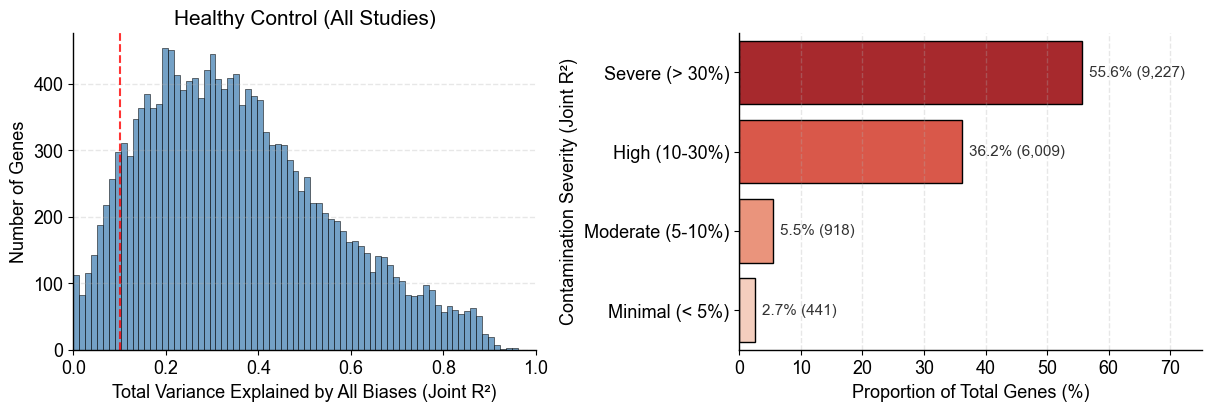

In [7]:
from config import EDA_GENE_BIAS_HC_DIR

EDA_GENE_BIAS_HC_DIR.mkdir(parents=True, exist_ok=True)
plot_gene_wise_bias_summary(
    df_hc_detail,
    group_name="Healthy Control (All Studies)",
    save_path=EDA_GENE_BIAS_HC_DIR / "gene_wise_bias_rda_summary.png",
)


 > Chalasani et al.  (n=993)

--- [Chalasani et al.] Vectorized Gene-wise Partial RDA ---


[Chalasani et al.] Valid samples : 993


[Chalasani et al.] Genes analyzed (≥10% expressed) : 15,641
[Chalasani et al.] Computing multivariate R² via orthogonal projection...


 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.8806   0.1268                 6943     > 10%
                Unique: log(Total Reads)  0.0724   0.0045                   19      > 5%
               Unique: Spliced Reads (%)  0.6198   0.0181                 1352      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.1142   0.0061                   85      > 5%
                   Unique: rRNA Fraction  0.0518   0.0018                    1      > 5%
       Unique: RNA Degradation (3' Bias)  0.0881   0.0036                   33      > 5%
                  Unique: Platelet Score  0.3558   0.0138                 1078      > 5%
                         Unique: GC Bias  0.0959   0.0041                   57      > 5%
                Unique: Gene Length Bias  0.0707   0.0042                   42      > 5%
                            Unique: NG80  0.0718   0.0029  

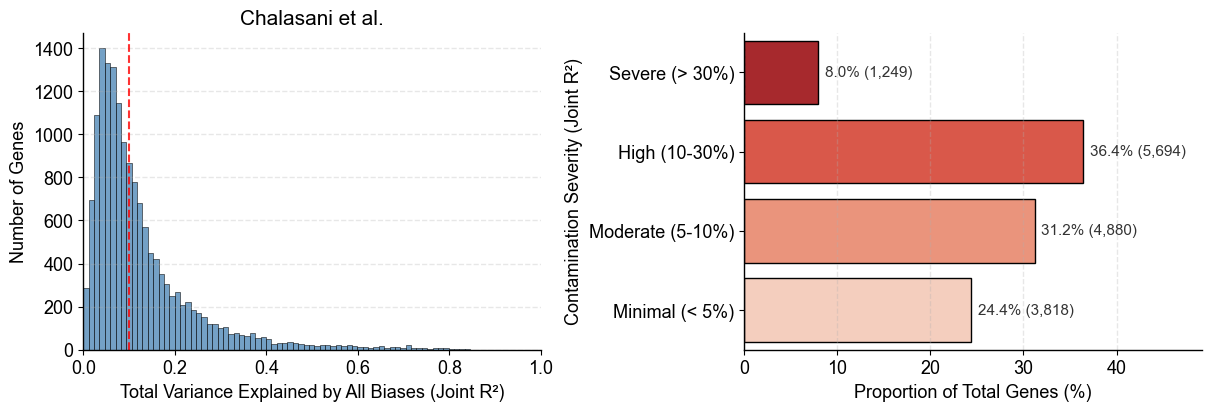


 > Toden et al.  (n=331)

--- [Toden et al.] Vectorized Gene-wise Partial RDA ---


[Toden et al.] Valid samples : 330
[Toden et al.] Genes analyzed (≥10% expressed) : 18,373
[Toden et al.] Computing multivariate R² via orthogonal projection...


 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.9346   0.2528                13635     > 10%
                Unique: log(Total Reads)  0.0929   0.0045                   47      > 5%
               Unique: Spliced Reads (%)  0.1311   0.0120                  841      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.1788   0.0077                  328      > 5%
                   Unique: rRNA Fraction  0.0514   0.0025                    1      > 5%
       Unique: RNA Degradation (3' Bias)  0.2324   0.0146                 1104      > 5%
                  Unique: Platelet Score  0.3666   0.0145                 1192      > 5%
                         Unique: GC Bias  0.1761   0.0085                  481      > 5%
                Unique: Gene Length Bias  0.2300   0.0122                  816      > 5%
                            Unique: NG80  0.1645   0.0029  

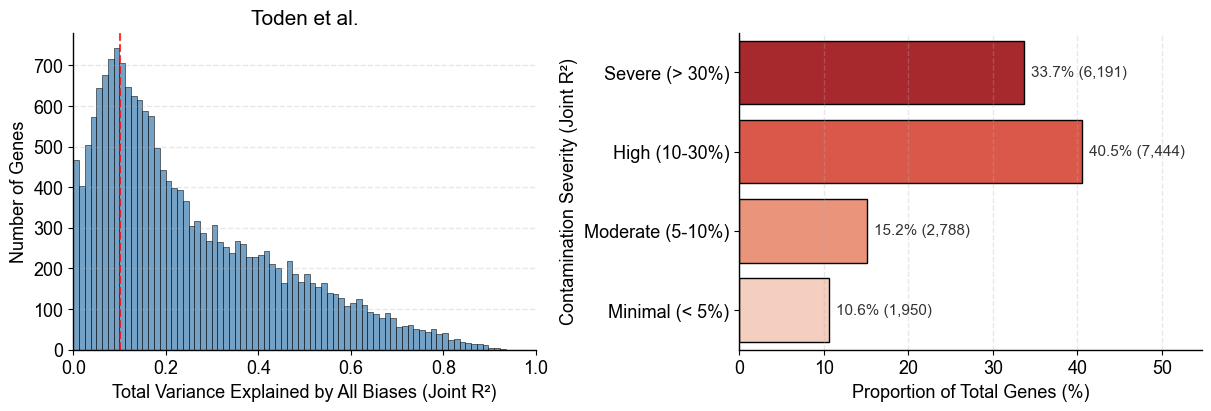


 > Moore et al.  (n=277)

--- [Moore et al.] Vectorized Gene-wise Partial RDA ---


[Moore et al.] Valid samples : 277
[Moore et al.] Genes analyzed (≥10% expressed) : 15,024
[Moore et al.] Computing multivariate R² via orthogonal projection...


 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.8975   0.2054                11851     > 10%
                Unique: log(Total Reads)  0.0824   0.0032                   10      > 5%
               Unique: Spliced Reads (%)  0.1111   0.0032                   48      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.1873   0.0057                  254      > 5%
                   Unique: rRNA Fraction  0.1120   0.0035                   31      > 5%
       Unique: RNA Degradation (3' Bias)  0.1506   0.0041                   74      > 5%
                  Unique: Platelet Score  0.3900   0.0124                  934      > 5%
                         Unique: GC Bias  0.1841   0.0045                   54      > 5%
                Unique: Gene Length Bias  0.3005   0.0143                 1110      > 5%
                            Unique: NG80  0.1266   0.0026  

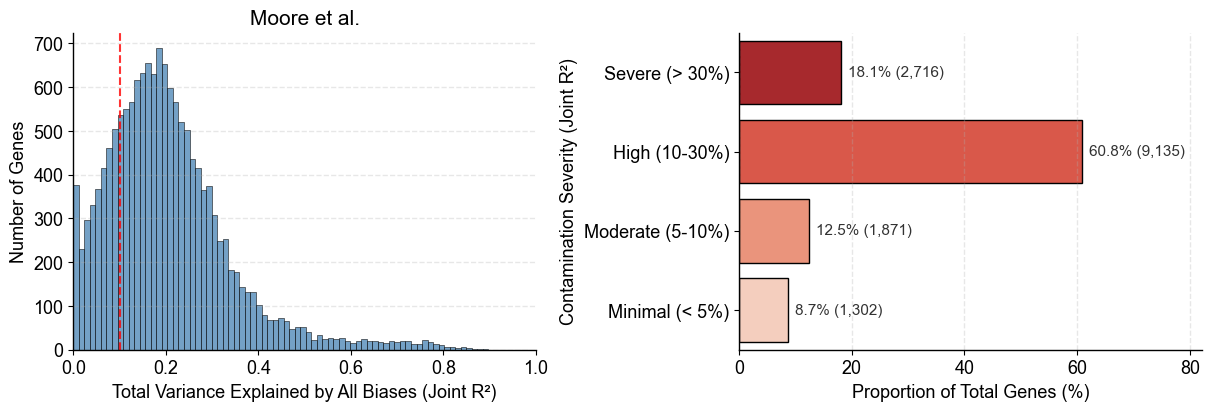


 > Moufarrej et al.  (n=256)

--- [Moufarrej et al.] Vectorized Gene-wise Partial RDA ---


[Moufarrej et al.] Valid samples : 256
[Moufarrej et al.] Genes analyzed (≥10% expressed) : 15,816
[Moufarrej et al.] Computing multivariate R² via orthogonal projection...


 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.9159   0.2496                12172     > 10%
                Unique: log(Total Reads)  0.1238   0.0039                   39      > 5%
               Unique: Spliced Reads (%)  0.0784   0.0030                   11      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.1109   0.0051                  167      > 5%
                   Unique: rRNA Fraction  0.1033   0.0031                   15      > 5%
       Unique: RNA Degradation (3' Bias)  0.1172   0.0044                  105      > 5%
                  Unique: Platelet Score  0.1715   0.0066                  318      > 5%
                         Unique: GC Bias  0.1861   0.0079                  410      > 5%
                Unique: Gene Length Bias  0.0977   0.0049                   85      > 5%
                            Unique: NG80  0.0984   0.0051  

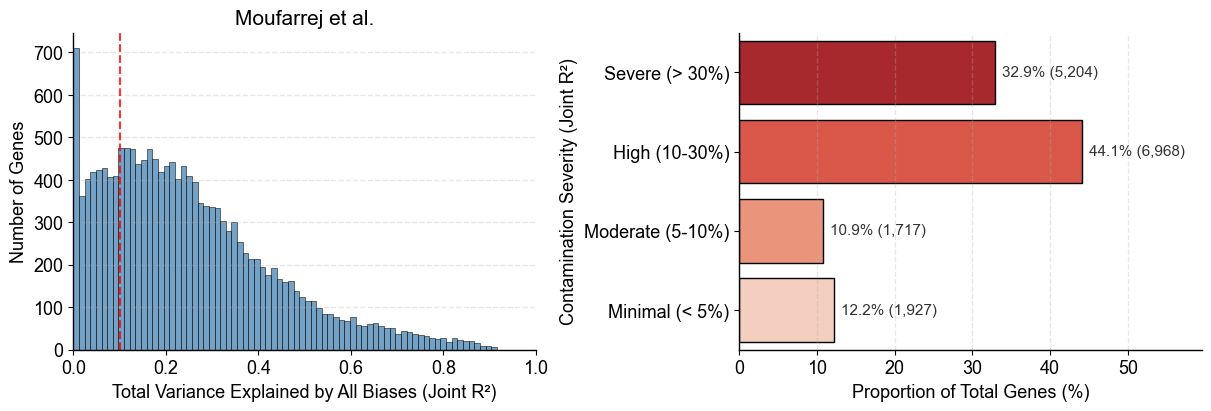


 > Chang et al.  (n=205)

--- [Chang et al.] Vectorized Gene-wise Partial RDA ---


[Chang et al.] Valid samples : 205
[Chang et al.] Genes analyzed (≥10% expressed) : 17,121
[Chang et al.] Computing multivariate R² via orthogonal projection...


 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.9623   0.2478                12405     > 10%
                Unique: log(Total Reads)  0.1462   0.0070                  348      > 5%
               Unique: Spliced Reads (%)  0.1160   0.0043                   88      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.1347   0.0043                  109      > 5%
                   Unique: rRNA Fraction  0.0885   0.0049                   86      > 5%
       Unique: RNA Degradation (3' Bias)  0.1374   0.0045                  138      > 5%
                  Unique: Platelet Score  0.2029   0.0093                  799      > 5%
                         Unique: GC Bias  0.2561   0.0098                  686      > 5%
                Unique: Gene Length Bias  0.1231   0.0050                  167      > 5%
                            Unique: NG80  0.0923   0.0037  

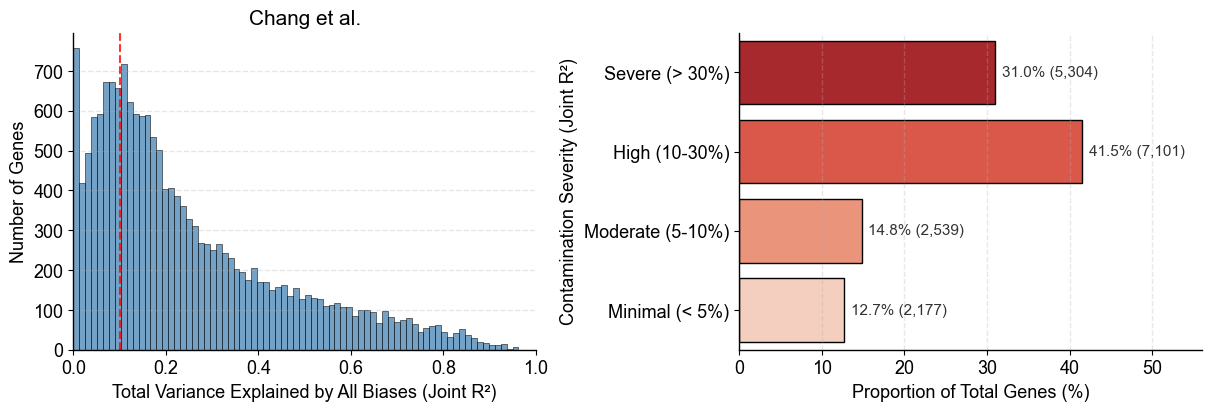


 > Chen et al.  (n=176)

--- [Chen et al.] Vectorized Gene-wise Partial RDA ---


[Chen et al.] Valid samples : 176
[Chen et al.] Genes analyzed (≥10% expressed) : 17,732
[Chen et al.] Computing multivariate R² via orthogonal projection...
 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.9143   0.4766                17301     > 10%
                Unique: log(Total Reads)  0.2636   0.0088                  339      > 5%
               Unique: Spliced Reads (%)  0.2743   0.0086                  483      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.3125   0.0174                 1831      > 5%
                   Unique: rRNA Fraction  0.2586   0.0108                  773      > 5%
       Unique: RNA Degradation (3' Bias)  0.2847   0.0077                  322      > 5%
                  Unique: Platelet Score  0.4486   0.0229                 2411      > 5%
                         Unique: GC Bias  0.2691   0.0099                  640 

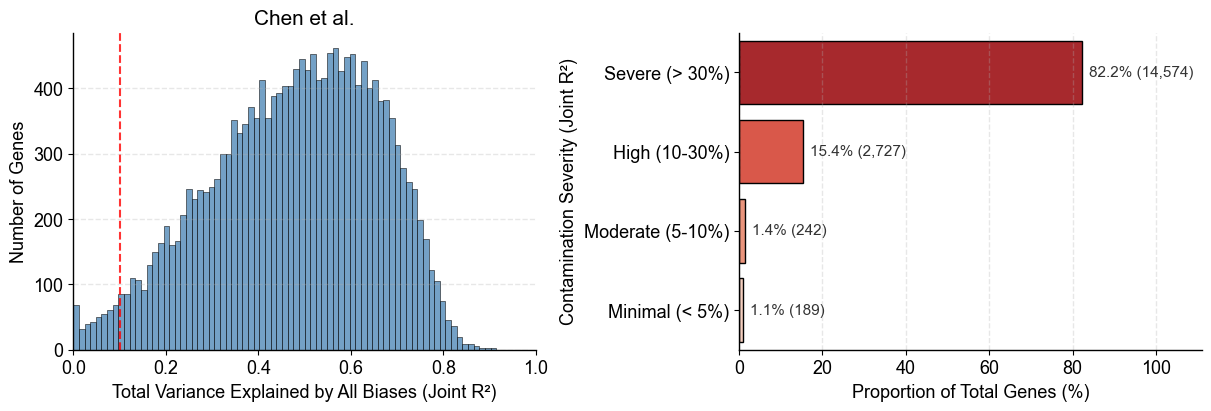


 > Gardella et al.  (n=163)

--- [Gardella et al.] Vectorized Gene-wise Partial RDA ---


[Gardella et al.] Valid samples : 163
[Gardella et al.] Genes analyzed (≥10% expressed) : 16,131
[Gardella et al.] Computing multivariate R² via orthogonal projection...
 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.9459   0.4090                13321     > 10%
                Unique: log(Total Reads)  0.1570   0.0053                  172      > 5%
               Unique: Spliced Reads (%)  0.2420   0.0110                  928      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.2273   0.0122                  962      > 5%
                   Unique: rRNA Fraction  0.1693   0.0088                  535      > 5%
       Unique: RNA Degradation (3' Bias)  0.4655   0.0183                 1557      > 5%
                  Unique: Platelet Score  0.3891   0.0168                 1509      > 5%
                         Unique: GC Bias  0.4061   0.0138          

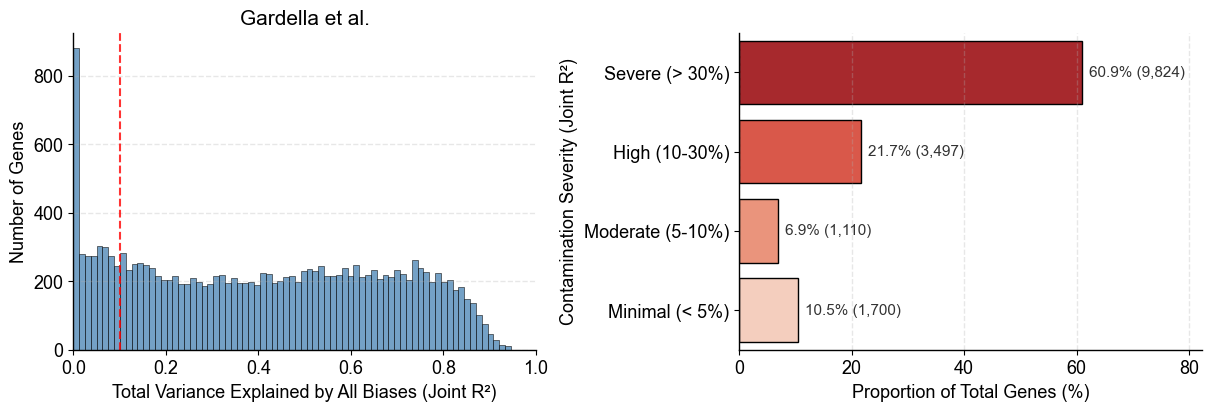


 > Roskams-Hieter B et al.  (n=88)

--- [Roskams-Hieter B et al.] Vectorized Gene-wise Partial RDA ---
[Roskams-Hieter B et al.] Valid samples : 88
[Roskams-Hieter B et al.] Genes analyzed (≥10% expressed) : 17,504
[Roskams-Hieter B et al.] Computing multivariate R² via orthogonal projection...


 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.9336   0.3367                14062     > 10%
                Unique: log(Total Reads)  0.1998   0.0085                  666      > 5%
               Unique: Spliced Reads (%)  0.1954   0.0092                  763      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.4279   0.0127                 1331      > 5%
                   Unique: rRNA Fraction  0.2731   0.0102                  957      > 5%
       Unique: RNA Degradation (3' Bias)  0.3911   0.0107                 1013      > 5%
                  Unique: Platelet Score  0.3400   0.0180                 1886      > 5%
                         Unique: GC Bias  0.4564   0.0156                 1667      > 5%
                Unique: Gene Length Bias  0.3198   0.0074                  576      > 5%
                            Unique: NG80  0.2182   0.0078  

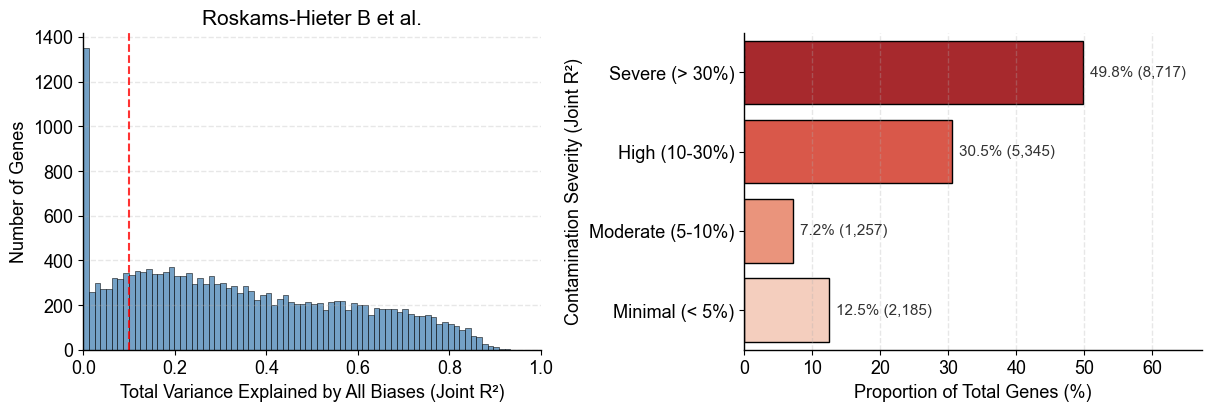


 > Ward Z et al.  (n=87)

--- [Ward Z et al.] Vectorized Gene-wise Partial RDA ---
[Ward Z et al.] Valid samples : 87
[Ward Z et al.] Genes analyzed (≥10% expressed) : 17,358
[Ward Z et al.] Computing multivariate R² via orthogonal projection...


 [Summary] Gene-level Contamination by Confounders
                      Variance_Component  Max_R2  Mean_R2  Genes_Highly_Biased Threshold
          ALL_BIASES_COMBINED (Joint R²)  0.9273   0.2708                12736     > 10%
                Unique: log(Total Reads)  0.2356   0.0103                  878      > 5%
               Unique: Spliced Reads (%)  0.2105   0.0099                  752      > 5%
Unique: gDNA Contamination (Intron/Exon)  0.2318   0.0099                  896      > 5%
                   Unique: rRNA Fraction  0.3406   0.0168                 2034      > 5%
       Unique: RNA Degradation (3' Bias)  0.1544   0.0051                  283      > 5%
                  Unique: Platelet Score  0.3265   0.0144                 1623      > 5%
                         Unique: GC Bias  0.2324   0.0106                 1062      > 5%
                Unique: Gene Length Bias  0.2973   0.0114                 1213      > 5%
                            Unique: NG80  0.2698   0.0129  

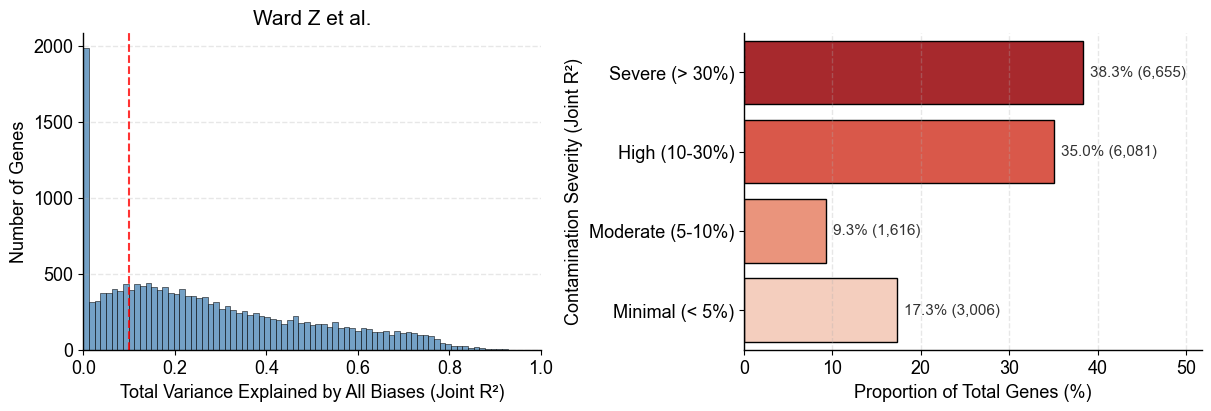

In [8]:
study_bias_metrics = combined_metrics + ["Phenotype_Processed"]
MIN_SAMPLES = 30
all_study_summaries = {}
for study in pipeline_rda.valid_studies:
    adata_study = adata_rda[adata_rda.obs["Author"] == study]
    n_samples = len(adata_study)
    if n_samples < MIN_SAMPLES:
        print(f"[Skip] {study}: {n_samples} (< {MIN_SAMPLES})")
        continue

    print(f"\n{'='*60}\n > {study}  (n={n_samples})\n{'='*60}")
    df_detail, df_summary = compute_gene_wise_bias_rda(
        adata_study,
        bias_metrics=study_bias_metrics,
        target_labels=None,
        group_name=study,
        layer="CPM_log1p",
        min_expressed_frac=0.1,
    )
    
    df_summary["Pct_Highly_Biased"] = (df_summary["Genes_Highly_Biased"] / len(df_detail)) * 100
    all_study_summaries[study] = {"detail": df_detail, "summary": df_summary}
    slug = study.replace(" ", "_").replace(".", "_")
    plot_gene_wise_bias_summary(
        df_detail,
        group_name=study,
        save_path=EDA_GENE_BIAS_HC_DIR / f"{slug}_gene_wise_bias_rda_summary.png",
    )